# Лабораторная работа 3. Градиентный спуск

**Студент:** Войтко Тимофей Дмитриевич, 351002  
**Вариант:** 9 (нечётный, L2-регуляризация)

В ноутбуке генерируется регрессионный набор с тремя признаками, реализуются пакетный и стохастический градиентный спуск, исследуется скорость обучения и сравнивается влияние коэффициента L2-регуляризации на веса.


## 1. Импорт библиотек и параметры эксперимента

NumPy выполняет векторные вычисления, pandas оформляет результаты в таблицы, matplotlib строит графики.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42
np.set_printoptions(precision=4, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Генерация и подготовка данных

`make_regression` создаёт задачу с известной линейной зависимостью. Используем три входных признака и один целевой столбец. Разобьём данные на обучающую и тестовую выборки, а признаки стандартизируем по обучающей выборке.

In [ ]:
X, y = make_regression(
    n_samples=500,
    n_features=3,
    n_informative=3,
    noise=12,
    bias=8,
    random_state=RANDOM_STATE,
)

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train_raw)
X_test_scaled = x_scaler.transform(X_test_raw)
y_mean = y_train_raw.mean()
y_scale = y_train_raw.std()
y_train = (y_train_raw - y_mean) / y_scale
y_test = (y_test_raw - y_mean) / y_scale

print(f"Обучающая выборка: {X_train_scaled.shape}")
print(f"Тестовая выборка: {X_test_scaled.shape}")
print("Число признаков:", X_train_scaled.shape[1])
print("Диапазон целевой переменной до масштабирования:", round(y.min(), 2), "..", round(y.max(), 2))

Обучающая выборка: (400, 3)
Тестовая выборка: (100, 3)
Число признаков: 3
Диапазон целевой переменной до масштабирования: -310.24 .. 328.31


## 3. Реализация пакетного градиентного спуска

Веса включают свободный коэффициент. На каждой итерации градиент считается сразу по всем объектам обучающей выборки. Остановка выполняется, когда изменение вектора весов становится меньше `epsilon` или заканчивается лимит итераций. Параметр `alpha` задаёт L2-регуляризацию; свободный коэффициент не штрафуется.

In [ ]:
def batch_gradient_descent(X, y, learning_rate=0.05, max_iter=3000, epsilon=1e-8, alpha=0.0):
    X_with_intercept = np.column_stack([np.ones(len(X)), X])
    weights = np.zeros(X_with_intercept.shape[1])
    losses = []
    for iteration in range(max_iter):
        errors = X_with_intercept @ weights - y
        gradient = (2 / len(y)) * (X_with_intercept.T @ errors)
        gradient[1:] += 2 * alpha * weights[1:]
        new_weights = weights - learning_rate * gradient
        losses.append(mean_squared_error(y, X_with_intercept @ new_weights))
        if np.linalg.norm(new_weights - weights) < epsilon:
            weights = new_weights
            break
        weights = new_weights
    return weights, np.asarray(losses), iteration + 1


def predict_linear(X, weights):
    return np.column_stack([np.ones(len(X)), X]) @ weights

## 4. Скорость обучения пакетного метода

Проверим несколько learning rate. Слишком малый шаг медленно уменьшает ошибку; слишком большой может приводить к колебаниям или расходимости. Для честного сравнения используем одинаковое число итераций и одинаковую инициализацию.

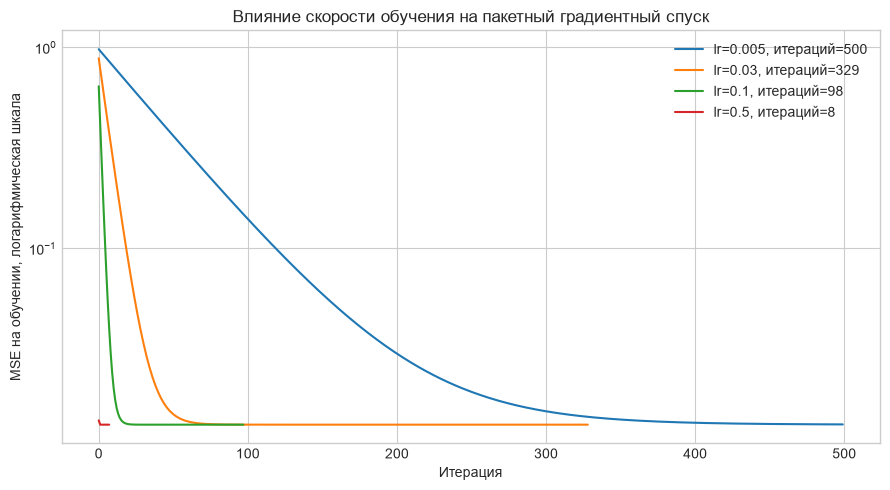

,learning_rate,iterations,final_train_mse
0,0.005,500,0.013326
1,0.030,329,0.013287
2,0.100,98,0.013287
3,0.500,8,0.013287


In [ ]:
learning_rates = [0.005, 0.03, 0.1, 0.5]
lr_results = {}
plt.figure(figsize=(9, 5))
for rate in learning_rates:
    w, loss, steps = batch_gradient_descent(
        X_train_scaled, y_train, learning_rate=rate, max_iter=500, epsilon=1e-10
    )
    lr_results[rate] = (w, loss, steps)
    plt.plot(loss, label=f"lr={rate}, итераций={steps}")
plt.yscale("log")
plt.xlabel("Итерация")
plt.ylabel("MSE на обучении, логарифмическая шкала")
plt.title("Влияние скорости обучения на пакетный градиентный спуск")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame([
    {"learning_rate": rate, "iterations": result[2], "final_train_mse": result[1][-1]}
    for rate, result in lr_results.items()
])

## 5. Стохастический градиентный спуск

В стохастическом варианте на каждом шаге случайно выбирается один объект, и веса обновляются по его ошибке. Чтобы сравнить с пакетным методом, будем сохранять MSE после каждой эпохи (одна эпоха — проход по всем объектам).

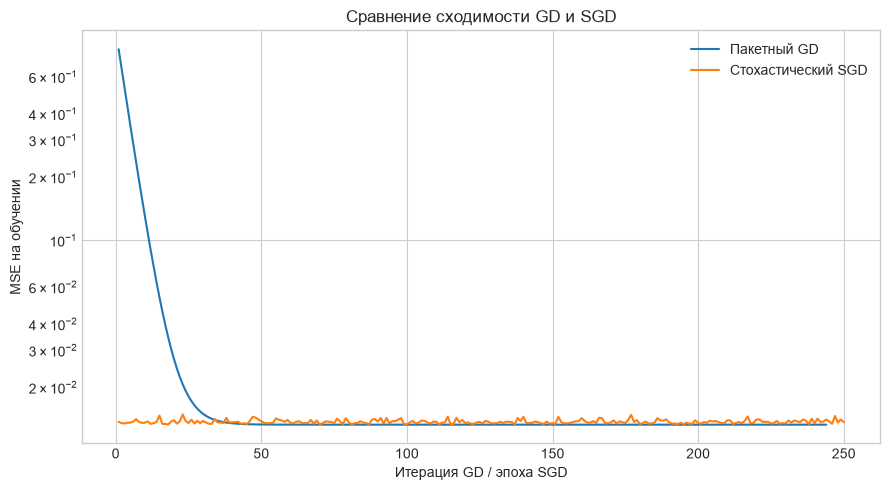

,method,updates,train_mse
0,Пакетный GD,244,0.013287
1,SGD,100000,0.013640


In [ ]:
def stochastic_gradient_descent(X, y, learning_rate=0.01, epochs=250, seed=42, alpha=0.0):
    rng = np.random.default_rng(seed)
    X_with_intercept = np.column_stack([np.ones(len(X)), X])
    weights = np.zeros(X_with_intercept.shape[1])
    losses = []
    for epoch in range(epochs):
        for index in rng.permutation(len(y)):
            error = X_with_intercept[index] @ weights - y[index]
            gradient = 2 * error * X_with_intercept[index]
            gradient[1:] += 2 * alpha * weights[1:]
            weights -= learning_rate * gradient
        losses.append(mean_squared_error(y, X_with_intercept @ weights))
    return weights, np.asarray(losses)


w_batch, loss_batch, batch_steps = batch_gradient_descent(
    X_train_scaled, y_train, learning_rate=0.05, max_iter=400, epsilon=1e-12
)
w_sgd, loss_sgd = stochastic_gradient_descent(
    X_train_scaled, y_train, learning_rate=0.01, epochs=250, seed=RANDOM_STATE
)

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(loss_batch) + 1), loss_batch, label="Пакетный GD")
plt.plot(np.arange(1, len(loss_sgd) + 1), loss_sgd, label="Стохастический SGD")
plt.xlabel("Итерация GD / эпоха SGD")
plt.ylabel("MSE на обучении")
plt.title("Сравнение сходимости GD и SGD")
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.show()

comparison = pd.DataFrame([
    {"method": "Пакетный GD", "updates": batch_steps, "train_mse": mean_squared_error(y_train, predict_linear(X_train_scaled, w_batch))},
    {"method": "SGD", "updates": len(y_train) * len(loss_sgd), "train_mse": mean_squared_error(y_train, predict_linear(X_train_scaled, w_sgd))},
])
comparison

## 6. Проверка качества на тестовой выборке

Метрики считаются на отложенных объектах, которые не участвовали в настройке весов. Возвращаем прогнозы к исходному масштабу целевой переменной.

In [ ]:
def original_scale_mse(X_scaled, y_scaled, weights):
    prediction_scaled = predict_linear(X_scaled, weights)
    prediction = prediction_scaled * y_scale + y_mean
    target = y_scaled * y_scale + y_mean
    return mean_squared_error(target, prediction)


pd.DataFrame([
    {"method": "Пакетный GD", "test_mse": original_scale_mse(X_test_scaled, y_test, w_batch)},
    {"method": "SGD", "test_mse": original_scale_mse(X_test_scaled, y_test, w_sgd)},
])

,method,test_mse
0,Пакетный GD,149.641325
1,SGD,160.666813


## 7. L2-регуляризация (вариант 9)

L2-регуляризация добавляет к функции потерь штраф `alpha * sum(w_j**2)`. Больший `alpha` сильнее притягивает коэффициенты к нулю. Проверим ровно 20 значений от 0,001 до 1000 и построим зависимости всех коэффициентов от `alpha`.

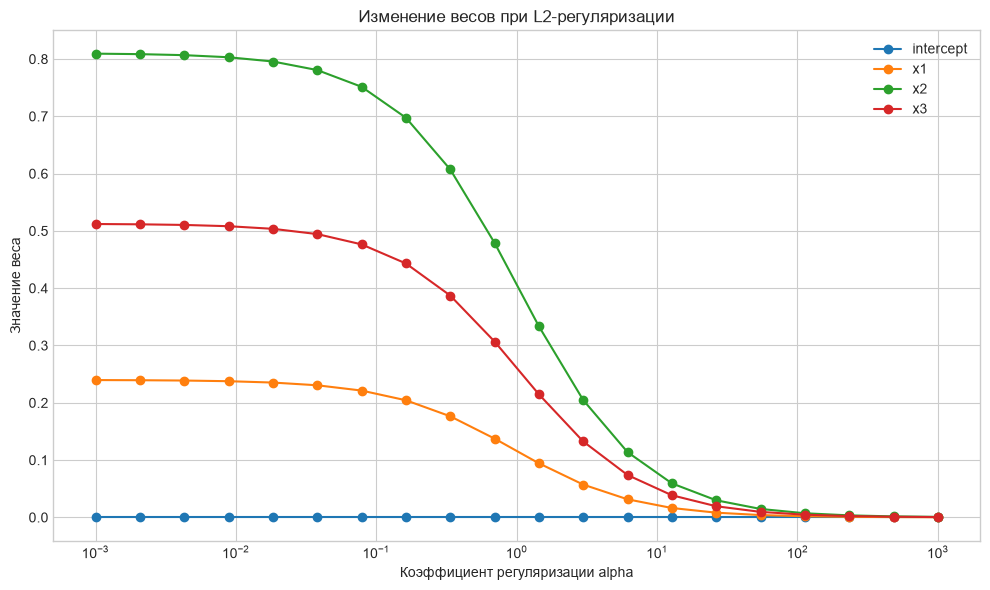

Количество коэффициентов регуляризации: 20
Диапазон alpha: 0.001 .. 1000.0


,intercept,w1,w2,w3,alpha
0,-9.877859e-17,0.239653,0.809382,0.512029,0.001000
1,-7.860173e-17,0.239380,0.808524,0.511503,0.002069
2,-7.591453e-17,0.238816,0.806753,0.510417,0.004281
3,-4.451472e-17,0.237658,0.803113,0.508186,0.008859
4,-5.163602e-17,0.235297,0.795685,0.503631,0.018330


In [ ]:
alphas = np.logspace(-3, 3, 20)
regularized_weights = []
for alpha in alphas:
    stable_rate = 0.8 / (np.linalg.norm(X_train_scaled.T @ X_train_scaled / len(y_train), ord=2) + 2 * alpha)
    weights, loss, steps = batch_gradient_descent(
        X_train_scaled,
        y_train,
        learning_rate=stable_rate,
        max_iter=5000,
        epsilon=1e-9,
        alpha=alpha,
    )
    regularized_weights.append(weights)
regularized_weights = np.asarray(regularized_weights)

plt.figure(figsize=(10, 6))
for index, name in enumerate(["intercept", "x1", "x2", "x3"]):
    plt.plot(alphas, regularized_weights[:, index], marker="o", label=name)
plt.xscale("log")
plt.xlabel("Коэффициент регуляризации alpha")
plt.ylabel("Значение веса")
plt.title("Изменение весов при L2-регуляризации")
plt.legend()
plt.tight_layout()
plt.show()

print("Количество коэффициентов регуляризации:", len(alphas))
print("Диапазон alpha:", alphas[0], "..", alphas[-1])
pd.DataFrame(regularized_weights, columns=["intercept", "w1", "w2", "w3"]).assign(alpha=alphas).head()

## 8. Выводы

Сравните графики и таблицы: как меняется скорость снижения MSE при разных learning rate; насколько шумнее траектория SGD и сколько обновлений ему требуется; как L2-регуляризация уменьшает абсолютные значения весов. Итоговые наблюдения приведены ниже после выполнения ноутбука.

In [ ]:
best_lr = min(lr_results, key=lambda rate: lr_results[rate][1][-1])
print(f"Минимальная итоговая MSE в эксперименте learning rate получена при lr={best_lr}.")
print("Пакетный GD обновляет веса один раз за итерацию по всей выборке; SGD — после каждого случайного объекта.")
print("При увеличении alpha коэффициенты признаков в целом сильнее стягиваются к нулю.")

Минимальная итоговая MSE в эксперименте learning rate получена при lr=0.1.
Пакетный GD обновляет веса один раз за итерацию по всей выборке; SGD — после каждого случайного объекта.
При увеличении alpha коэффициенты признаков в целом сильнее стягиваются к нулю.
